# Trainability as differential information transmission in variational quantum circuits

Companion notebook for:

> F. Ailabouni and R. Casado, **"Trainability as differential information transmission in variational quantum circuits."**

This notebook reproduces the numerical experiments and figures of the paper (Section 5, *Numerical validation of Jacobian-mediated trainability*). 

**Reproducibility.** All experiments use a fixed global seed (`GLOBAL_SEED = 1234`) plus experiment-specific seeds, exact noiseless statevector simulation (no shots/hardware noise), and centered finite differences for gradients and the metric tensor. 


## Notebook ↔ paper correspondence

| Notebook section | Paper reference | Output |
|---|---|---|
| Validation 0 | consistency check for the numerical engine (modal identity, Eq. 12) | `fig_validation0_modal_identity.pdf` |
| Validation I | Section 5.2 — spectral vs. alignment suppression | Figure 1 |
| Validation II | Section 5.3 — DLA-equivalent circuits, Jacobian geometry | Figures 2–3 |
| Validation III | Section 5.4 — scaling of spectral accessibility and alignment | Figure 4 |
| Validation IV | Section 5.5 — predictive power of Jacobian diagnostics | Figure 5, Table 1 |
| Validation V | Section 5.6 — second-order geometric effects (Hessian decomposition) | Figure 6 |

Figures are written to `figures_jacobian_qfim/` and the underlying dataframes to `data_jacobian_qfim/` (see the export cell at the end of the notebook).


In [1]:
# Environment setup.
# Tested with: Python 3.11, NumPy 2.0, SciPy 1.14, Qiskit 1.2 (see requirements.txt).
# Run this cell on Google Colab or any fresh environment to install missing dependencies.
try:
    import qiskit
    print("Qiskit version:", qiskit.__version__)
except ImportError:
    %pip install -q "qiskit>=1.2" "numpy>=2.0" "scipy>=1.14" pandas matplotlib
    import qiskit
    print("Qiskit version:", qiskit.__version__)


Qiskit version: 2.3.1


In [2]:
import os
import math
import time
import itertools
from dataclasses import dataclass
from typing import Callable, Dict, List, Tuple, Optional, Sequence

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp

np.set_printoptions(precision=5, suppress=True)

FIG_DIR = "figures_jacobian_qfim"
os.makedirs(FIG_DIR, exist_ok=True)

GLOBAL_SEED = 1234
rng = np.random.default_rng(GLOBAL_SEED)

# Metric convention
# -----------------
# The numerical engine uses pure-state tangent vectors.  For consistency with the
# Hilbert--Schmidt density-matrix Jacobian used in the paper,
# Tr(d rho_i d rho_j) = 4 g_FS, so we multiply the Fubini--Study metric by 4.
# Setting METRIC_SCALE = 1.0 recovers the raw Fubini--Study convention.
METRIC_SCALE = 4.0
METRIC_NAME = "Hilbert-Schmidt density-matrix metric = 4 × Fubini-Study"
print("Metric convention:", METRIC_NAME)


Metric convention: Hilbert-Schmidt density-matrix metric = 4 × Fubini-Study


## Core statevector engine

The simulator below is intentionally lightweight. We use Qiskit to construct circuits for documentation/visual inspection, but all metrics are computed directly from statevectors. This makes finite differences and repeated sampling much faster and easier to control.

In [3]:
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}


def RX(theta):
    return np.cos(theta/2)*I2 - 1j*np.sin(theta/2)*X


def RY(theta):
    return np.cos(theta/2)*I2 - 1j*np.sin(theta/2)*Y


def RZ(theta):
    return np.cos(theta/2)*I2 - 1j*np.sin(theta/2)*Z


def RXX(theta):
    XX = np.kron(X, X)
    return np.cos(theta/2)*np.eye(4, dtype=complex) - 1j*np.sin(theta/2)*XX


def RZZ(theta):
    ZZ = np.kron(Z, Z)
    return np.cos(theta/2)*np.eye(4, dtype=complex) - 1j*np.sin(theta/2)*ZZ


def zero_state(n: int) -> np.ndarray:
    psi = np.zeros(2**n, dtype=complex)
    psi[0] = 1.0
    return psi


def apply_one_qubit_gate(psi: np.ndarray, U: np.ndarray, q: int, n: int) -> np.ndarray:
    # Qubit indexing: q=0 is the leftmost/logical first qubit.
    tensor = psi.reshape([2]*n)
    axes = [q] + [i for i in range(n) if i != q]
    inv_axes = np.argsort(axes)
    tensor_perm = np.transpose(tensor, axes).reshape(2, -1)
    updated = U @ tensor_perm
    updated = updated.reshape([2] + [2]*(n-1))
    return np.transpose(updated, inv_axes).reshape(-1)


def apply_two_qubit_gate(psi: np.ndarray, U4: np.ndarray, q1: int, q2: int, n: int) -> np.ndarray:
    if q1 == q2:
        raise ValueError("q1 and q2 must be different")
    axes_front = [q1, q2]
    axes_rest = [i for i in range(n) if i not in axes_front]
    axes = axes_front + axes_rest
    inv_axes = np.argsort(axes)
    tensor = psi.reshape([2]*n)
    tensor_perm = np.transpose(tensor, axes).reshape(4, -1)
    updated = U4 @ tensor_perm
    updated = updated.reshape([2, 2] + [2]*(n-2))
    return np.transpose(updated, inv_axes).reshape(-1)


def apply_pauli_string(psi: np.ndarray, pauli_string: str) -> np.ndarray:
    n = len(pauli_string)
    out = psi
    for q, p in enumerate(pauli_string):
        if p != "I":
            out = apply_one_qubit_gate(out, PAULI[p], q, n)
    return out


def expectation_pauli(psi: np.ndarray, pauli_string: str) -> float:
    return float(np.real(np.vdot(psi, apply_pauli_string(psi, pauli_string))))


def expectation_sparse_pauli(psi: np.ndarray, op: SparsePauliOp) -> float:
    # Qiskit Pauli labels are strings such as 'ZI'. We keep the same left-to-right convention.
    val = 0.0 + 0.0j
    for label, coeff in zip(op.paulis.to_labels(), op.coeffs):
        val += coeff * np.vdot(psi, apply_pauli_string(psi, label))
    return float(np.real(val))

## Ansatz specification

Each ansatz is represented by a list of gates. A gate may be parameterized, with `param` giving the index in the parameter vector. This is convenient for finite differences, parameter-shift gradients, QFIM estimation and circuit drawing.

In [4]:
@dataclass
class GateSpec:
    name: str
    qubits: Tuple[int, ...]
    param: Optional[int] = None
    fixed_angle: Optional[float] = None

@dataclass
class AnsatzSpec:
    name: str
    n_qubits: int
    n_params: int
    gates: List[GateSpec]
    generator_labels: List[str]
    description: str = ""


def run_ansatz_state(ansatz: AnsatzSpec, theta: np.ndarray) -> np.ndarray:
    psi = zero_state(ansatz.n_qubits)
    for g in ansatz.gates:
        angle = g.fixed_angle if g.param is None else theta[g.param]
        if g.name == "rx":
            psi = apply_one_qubit_gate(psi, RX(angle), g.qubits[0], ansatz.n_qubits)
        elif g.name == "ry":
            psi = apply_one_qubit_gate(psi, RY(angle), g.qubits[0], ansatz.n_qubits)
        elif g.name == "rz":
            psi = apply_one_qubit_gate(psi, RZ(angle), g.qubits[0], ansatz.n_qubits)
        elif g.name == "rxx":
            psi = apply_two_qubit_gate(psi, RXX(angle), g.qubits[0], g.qubits[1], ansatz.n_qubits)
        elif g.name == "rzz":
            psi = apply_two_qubit_gate(psi, RZZ(angle), g.qubits[0], g.qubits[1], ansatz.n_qubits)
        else:
            raise ValueError(f"Unknown gate {g.name}")
    return psi / np.linalg.norm(psi)


def ansatz_to_qiskit(ansatz: AnsatzSpec, theta: Optional[np.ndarray] = None) -> QuantumCircuit:
    qc = QuantumCircuit(ansatz.n_qubits)
    for g in ansatz.gates:
        angle = g.fixed_angle if g.param is None else (float(theta[g.param]) if theta is not None else 0.0)
        if g.name == "rx":
            qc.rx(angle, g.qubits[0])
        elif g.name == "ry":
            qc.ry(angle, g.qubits[0])
        elif g.name == "rz":
            qc.rz(angle, g.qubits[0])
        elif g.name == "rxx":
            qc.rxx(angle, g.qubits[0], g.qubits[1])
        elif g.name == "rzz":
            qc.rzz(angle, g.qubits[0], g.qubits[1])
        else:
            raise ValueError(f"Unknown gate {g.name}")
    return qc


def random_theta(ansatz: AnsatzSpec, seed: Optional[int] = None, scale: float = 2*np.pi) -> np.ndarray:
    local_rng = np.random.default_rng(seed)
    return local_rng.uniform(-scale/2, scale/2, size=ansatz.n_params)

In [5]:
def single_qubit_A() -> AnsatzSpec:
    # U_A = RZ(phi) RX(theta), acting on |0>.
    gates = [GateSpec("rx", (0,), 0), GateSpec("rz", (0,), 1)]
    return AnsatzSpec("1q_A_RZ_after_RX", 1, 2, gates, ["X0", "Z0"], "U_A = RZ(phi) RX(theta)")


def single_qubit_B() -> AnsatzSpec:
    # U_B = RX(theta) RZ(phi), i.e. RZ acts first on |0> and is stabilizer-inactive.
    gates = [GateSpec("rz", (0,), 1), GateSpec("rx", (0,), 0)]
    return AnsatzSpec("1q_B_RX_after_RZ", 1, 2, gates, ["X0", "Z0"], "U_B = RX(theta) RZ(phi)")


def two_qubit_A() -> AnsatzSpec:
    gates = [GateSpec("rxx", (0, 1), 0), GateSpec("rz", (0,), 1)]
    return AnsatzSpec("2q_A_RZ_after_RXX", 2, 2, gates, ["X0X1", "Z0"], "U_A = RZ_0(phi) RXX_01(theta)")


def two_qubit_B() -> AnsatzSpec:
    gates = [GateSpec("rz", (0,), 1), GateSpec("rxx", (0, 1), 0)]
    return AnsatzSpec("2q_B_RXX_after_RZ", 2, 2, gates, ["X0X1", "Z0"], "U_B = RXX_01(theta) RZ_0(phi)")


def dla_equiv_chain_A(n: int, layers: int = 1) -> AnsatzSpec:
    # Entangling RXX chain first, then RZ rotations. RZ rotations act after leaving the stabilizer.
    gates = []
    p = 0
    for _ in range(layers):
        for q in range(n-1):
            gates.append(GateSpec("rxx", (q, q+1), p)); p += 1
        for q in range(n):
            gates.append(GateSpec("rz", (q,), p)); p += 1
    labels = [f"X{q}X{q+1}" for q in range(n-1)] + [f"Z{q}" for q in range(n)]
    return AnsatzSpec(f"chain_A_n{n}_L{layers}", n, p, gates, labels, "RXX chain followed by RZ block")


def dla_equiv_chain_B(n: int, layers: int = 1) -> AnsatzSpec:
    # Same generator multiset as A, but stabilizer rotations are placed before RXX chains in each layer.
    gates = []
    p = 0
    for _ in range(layers):
        for q in range(n):
            gates.append(GateSpec("rz", (q,), p)); p += 1
        for q in range(n-1):
            gates.append(GateSpec("rxx", (q, q+1), p)); p += 1
    labels = [f"X{q}X{q+1}" for q in range(n-1)] + [f"Z{q}" for q in range(n)]
    return AnsatzSpec(f"chain_B_n{n}_L{layers}", n, p, gates, labels, "RZ block followed by RXX chain")


def hea_ansatz(n: int, layers: int = 2, entangler: str = "rzz") -> AnsatzSpec:
    gates = []
    p = 0
    for ell in range(layers):
        for q in range(n):
            gates.append(GateSpec("ry", (q,), p)); p += 1
            gates.append(GateSpec("rz", (q,), p)); p += 1
        for q in range(n-1):
            gates.append(GateSpec(entangler, (q, q+1), p)); p += 1
    labels = ["RY", "RZ", entangler.upper()]
    return AnsatzSpec(f"HEA_n{n}_L{layers}_{entangler}", n, p, gates, labels, "Hardware-efficient ansatz")


def local_rxrz_ansatz(n: int, layers: int = 2) -> AnsatzSpec:
    gates = []
    p = 0
    for ell in range(layers):
        for q in range(n):
            gates.append(GateSpec("rx", (q,), p)); p += 1
            gates.append(GateSpec("rz", (q,), p)); p += 1
        for q in range(n-1):
            gates.append(GateSpec("rzz", (q, q+1), p)); p += 1
    labels = ["RX", "RZ", "ZZ"]
    return AnsatzSpec(f"Local_RXRZ_n{n}_L{layers}", n, p, gates, labels, "Local RX/RZ plus nearest-neighbour RZZ")


def random_permutation_same_generators(base: AnsatzSpec, seed: int, name_suffix: str = "perm") -> AnsatzSpec:
    local_rng = np.random.default_rng(seed)
    gates = list(base.gates)
    local_rng.shuffle(gates)
    # Re-index parameters after shuffling.
    new_gates = []
    for p, g in enumerate(gates):
        new_gates.append(GateSpec(g.name, g.qubits, p, g.fixed_angle))
    return AnsatzSpec(base.name + f"_{name_suffix}_{seed}", base.n_qubits, len(new_gates), new_gates, base.generator_labels, "Random permutation of the same gate multiset")

## Gradients, QFIM/metric tensor and modal diagnostics

In [6]:
def cost_value(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp) -> float:
    psi = run_ansatz_state(ansatz, theta)
    return expectation_sparse_pauli(psi, observable)


def finite_difference_gradient(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp, eps: float = 1e-6) -> np.ndarray:
    grad = np.zeros(ansatz.n_params, dtype=float)
    for k in range(ansatz.n_params):
        tp = theta.copy(); tm = theta.copy()
        tp[k] += eps; tm[k] -= eps
        grad[k] = (cost_value(ansatz, tp, observable) - cost_value(ansatz, tm, observable)) / (2*eps)
    return grad


def state_derivatives(ansatz: AnsatzSpec, theta: np.ndarray, eps: float = 1e-6) -> List[np.ndarray]:
    derivs = []
    for k in range(ansatz.n_params):
        tp = theta.copy(); tm = theta.copy()
        tp[k] += eps; tm[k] -= eps
        derivs.append((run_ansatz_state(ansatz, tp) - run_ansatz_state(ansatz, tm)) / (2*eps))
    return derivs


def fs_metric_tensor(ansatz: AnsatzSpec, theta: np.ndarray, eps: float = 1e-6) -> np.ndarray:
    psi = run_ansatz_state(ansatz, theta)
    derivs = state_derivatives(ansatz, theta, eps=eps)
    p = ansatz.n_params
    G = np.zeros((p, p), dtype=float)
    overlaps_with_state = np.array([np.vdot(d, psi) for d in derivs])
    for i in range(p):
        for j in range(p):
            val = np.vdot(derivs[i], derivs[j]) - overlaps_with_state[i] * np.conj(overlaps_with_state[j])
            G[i, j] = np.real(val)
    # Symmetrize to remove finite-difference noise and convert convention.
    # For pure states, the Hilbert--Schmidt metric on density matrices is
    # Tr(d rho_i d rho_j) = 4 g_FS.  METRIC_SCALE=4 makes numerical singular
    # values match the density-matrix Jacobian convention used in the paper.
    return METRIC_SCALE * 0.5 * (G + G.T)


def modal_diagnostics(ansatz: AnsatzSpec, theta: np.ndarray, observable: SparsePauliOp, eps: float = 1e-6, rank_tol: float = 1e-10) -> Dict:
    grad = finite_difference_gradient(ansatz, theta, observable, eps=eps)
    G = fs_metric_tensor(ansatz, theta, eps=eps)
    evals, evecs = np.linalg.eigh(G)
    idx = np.argsort(evals)[::-1]
    evals = np.maximum(evals[idx], 0.0)
    evecs = evecs[:, idx]
    vgrad = evecs.T @ grad
    align = np.zeros_like(evals)
    mask = evals > rank_tol
    align[mask] = (vgrad[mask]**2) / evals[mask]
    modal_contrib = evals * align
    grad_norm2 = float(np.dot(grad, grad))
    recon_norm2 = float(np.sum(modal_contrib))

    # Active singular spectrum: singular modes that actually receive gradient
    # contribution.  This is useful to detect shallow regimes in which all
    # active modes have the same canonical singular value and the experiment is
    # effectively testing alignment only.
    active_tol = max(1e-14, 1e-8 * max(grad_norm2, 1e-15))
    active_mask = (modal_contrib > active_tol) & (evals > rank_tol)
    active_sigma2 = evals[active_mask]
    if active_sigma2.size > 0:
        active_sigma2_min = float(np.min(active_sigma2))
        active_sigma2_max = float(np.max(active_sigma2))
        active_sigma2_ratio = float(active_sigma2_max / max(active_sigma2_min, 1e-300))
        active_sigma2_logspread = float(np.log10(active_sigma2_ratio))
    else:
        active_sigma2_min = 0.0
        active_sigma2_max = 0.0
        active_sigma2_ratio = np.nan
        active_sigma2_logspread = np.nan

    return {
        "grad": grad,
        "G": G,
        "sigma2": evals,
        "sigma": np.sqrt(evals),
        "V": evecs,
        "vgrad": vgrad,
        "align": align,
        "modal_contrib": modal_contrib,
        "grad_norm2": grad_norm2,
        "recon_norm2": recon_norm2,
        "rel_error": abs(grad_norm2 - recon_norm2) / max(1e-15, grad_norm2),
        "rank_eps": int(np.sum(evals > rank_tol)),
        "spec_sum": float(np.sum(evals)),
        "align_sum": float(np.sum(align)),
        "sigma_max": float(np.sqrt(evals[0])) if len(evals) else 0.0,
        "sigma_min_pos": float(np.sqrt(evals[mask][-1])) if np.any(mask) else 0.0,
        "active_n": int(np.sum(active_mask)),
        "active_sigma2_min": active_sigma2_min,
        "active_sigma2_max": active_sigma2_max,
        "active_sigma2_ratio": active_sigma2_ratio,
        "active_sigma2_logspread": active_sigma2_logspread,
    }


def make_observable(label: str, coeff: float = 1.0) -> SparsePauliOp:
    return SparsePauliOp.from_list([(label, coeff)])


def local_Z(n: int, q: int = 0) -> SparsePauliOp:
    label = ["I"]*n
    label[q] = "Z"
    return make_observable("".join(label))


def local_X(n: int, q: int = 0) -> SparsePauliOp:
    label = ["I"]*n
    label[q] = "X"
    return make_observable("".join(label))


def global_Z(n: int) -> SparsePauliOp:
    return make_observable("Z"*n)


def global_mixed_phase_string(n: int) -> SparsePauliOp:
    """Symmetry-breaking global Pauli string.

    The pure global_Z observable commutes with the {RXX, RZ} chain generators,
    making chainA/chainB gradients vanish by exact symmetry rather than by
    Jacobian geometry.  This mixed global string is nonlocal but breaks that
    parity-Z symmetry, so it is a better global task for scaling diagnostics.
    """
    if n == 1:
        return make_observable("X")
    label = ["X"] * n
    label[0] = "Y"
    return make_observable("".join(label))


def nearest_neighbor_yx_observable(n: int, normalize: bool = True) -> SparsePauliOp:
    """Phase-sensitive nearest-neighbour observable.

    O = sum_q Y_q X_{q+1} / (n-1).

    This observable is designed for the DLA-equivalent A/B chain experiment:
    after RXX entanglers, final RZ rotations create relative phases that are
    visible to YX-type Pauli strings. If the same RZ rotations are placed before
    the entanglers, many of them act initially as stabilizer directions and their
    gradient components vanish or are strongly reduced.
    """
    if n < 2:
        return local_X(n, 0)
    coeff = 1.0 / (n - 1) if normalize else 1.0
    terms = []
    for q in range(n - 1):
        label = ["I"] * n
        label[q] = "Y"
        label[q + 1] = "X"
        terms.append(("".join(label), coeff))
    return SparsePauliOp.from_list(terms)


def nearest_neighbor_xy_yx_observable(n: int, normalize: bool = True) -> SparsePauliOp:
    """Symmetric phase-sensitive observable using XY and YX strings.

    O = sum_q (X_q Y_{q+1} + Y_q X_{q+1}) / (2(n-1)).
    This is useful as a robustness check for the phase-sensitive task.
    """
    if n < 2:
        return local_X(n, 0)
    coeff = 1.0 / (2 * (n - 1)) if normalize else 1.0
    terms = []
    for q in range(n - 1):
        label_yx = ["I"] * n
        label_yx[q] = "Y"
        label_yx[q + 1] = "X"
        terms.append(("".join(label_yx), coeff))

        label_xy = ["I"] * n
        label_xy[q] = "X"
        label_xy[q + 1] = "Y"
        terms.append(("".join(label_xy), coeff))
    return SparsePauliOp.from_list(terms)



def random_pauli_observable(n: int, seed: int, n_terms: int = 4) -> SparsePauliOp:
    local_rng = np.random.default_rng(seed)
    terms = []
    for _ in range(n_terms):
        label = "".join(local_rng.choice(list("IXYZ"), size=n))
        if set(label) == {"I"}:
            label = "Z" + "I"*(n-1)
        coeff = local_rng.normal()
        terms.append((label, coeff))
    return SparsePauliOp.from_list(terms)

# Validation 0 — computational engine and modal identity

In [7]:
def validation_0_modal_identity(n_samples: int = 50, max_n: int = 6, seed: int = 10, eps: float = 1e-6) -> pd.DataFrame:
    local_rng = np.random.default_rng(seed)
    rows = []
    for s in range(n_samples):
        n = int(local_rng.integers(1, max_n+1))
        L = int(local_rng.integers(1, 3))
        family = local_rng.choice(["hea", "local", "chainA", "chainB"])
        if family == "hea":
            ans = hea_ansatz(n, L, entangler="rzz")
        elif family == "local":
            ans = local_rxrz_ansatz(n, L)
        elif family == "chainA":
            ans = dla_equiv_chain_A(n, L)
        else:
            ans = dla_equiv_chain_B(n, L)
        obs = random_pauli_observable(n, seed=1000+s, n_terms=3)
        theta = local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
        diag = modal_diagnostics(ans, theta, obs, eps=eps)
        rows.append({
            "sample": s,
            "n": n,
            "L": L,
            "family": family,
            "p": ans.n_params,
            "grad_norm2": diag["grad_norm2"],
            "recon_norm2": diag["recon_norm2"],
            "rel_error": diag["rel_error"],
            "rank_eps": diag["rank_eps"],
            "sigma_max": diag["sigma_max"],
            "spec_sum": diag["spec_sum"],
            "align_sum": diag["align_sum"],
        })
    return pd.DataFrame(rows)

val0_df = validation_0_modal_identity(n_samples=40, max_n=5, seed=7)
val0_df.head(), val0_df["rel_error"].describe()

(   sample  n  L  family   p    grad_norm2  recon_norm2     rel_error  \
 0       0  5  2  chainA  18  3.407908e+00     3.407908  5.212455e-16   
 1       1  5  1     hea  14  8.998327e-02     0.089983  3.084526e-16   
 2       2  5  1  chainA   9  7.352506e-01     0.735251  3.019985e-16   
 3       3  2  1     hea   5  9.938109e-01     0.993811  2.234274e-16   
 4       4  1  1  chainA   1  1.109336e-19     0.000000  1.109336e-04   
 
    rank_eps  sigma_max   spec_sum  align_sum  
 0        18   1.485272  16.058260   3.272996  
 1        14   1.188746   7.377019   0.101941  
 2         9   1.245672   7.678137   0.735251  
 3         5   1.022500   3.142513   1.121887  
 4         0   0.000000   0.000000   0.000000  ,
 count    4.000000e+01
 mean     2.793887e-06
 std      1.753708e-05
 min      0.000000e+00
 25%      1.288703e-16
 50%      2.811611e-16
 75%      4.933650e-16
 max      1.109336e-04
 Name: rel_error, dtype: float64)

'figures_jacobian_qfim\\fig_validation0_modal_identity.pdf'

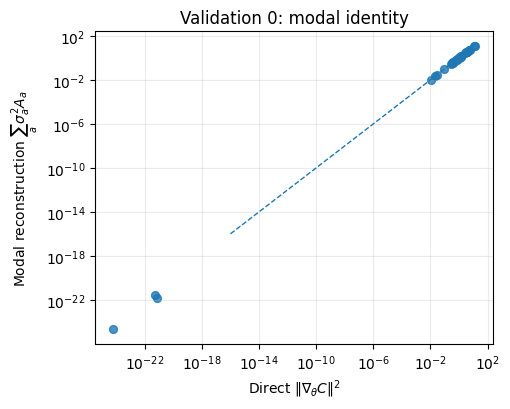

In [8]:
def plot_validation_0(df: pd.DataFrame, filename: str = "fig_validation0_modal_identity.pdf"):
    fig, ax = plt.subplots(figsize=(5.2, 4.2))
    x = df["grad_norm2"].to_numpy()
    y = df["recon_norm2"].to_numpy()
    ax.scatter(x, y, s=32, alpha=0.8)
    lo = max(min(x.min(), y.min()), 1e-16)
    hi = max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Direct $\|\nabla_\theta C\|^2$")
    ax.set_ylabel(r"Modal reconstruction $\sum_a \sigma_a^2 A_a$")
    ax.set_title("Validation 0: modal identity")
    ax.grid(True, which="both", alpha=0.25)
    fig.tight_layout()
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    return path

plot_validation_0(val0_df)

# Validation I — independent spectral and alignment suppression

In [9]:
def validation_I_one_qubit_grid(num: int = 200, eps: float = 1e-6) -> pd.DataFrame:
    ans = single_qubit_A()
    obs_X = make_observable("X")
    obs_Z = make_observable("Z")
    rows = []
    # Spectral suppression: phi = 0, theta approaches 0, cost X.
    for theta_val in np.linspace(1e-3, np.pi-1e-3, num):
        theta = np.array([theta_val, 0.0])
        diag = modal_diagnostics(ans, theta, obs_X, eps=eps)
        rows.append({
            "mechanism": "spectral_X_phi0",
            "theta": theta_val,
            "sigma2_mode2": diag["sigma2"][1],
            "align_mode2": diag["align"][1],
            "contrib_mode2": diag["modal_contrib"][1],
            "grad_norm2": diag["grad_norm2"],
        })
    # Alignment suppression: cost Z, choose generic phi.
    for theta_val in np.linspace(1e-3, np.pi-1e-3, num):
        theta = np.array([theta_val, 0.7])
        diag = modal_diagnostics(ans, theta, obs_Z, eps=eps)
        rows.append({
            "mechanism": "alignment_Z_phi07",
            "theta": theta_val,
            "sigma2_mode2": diag["sigma2"][1],
            "align_mode2": diag["align"][1],
            "contrib_mode2": diag["modal_contrib"][1],
            "grad_norm2": diag["grad_norm2"],
        })
    return pd.DataFrame(rows)

valI_df = validation_I_one_qubit_grid()
valI_df.head()

,mechanism,theta,sigma2_mode2,align_mode2,contrib_mode2,grad_norm2
0,spectral_X_phi0,0.001000,9.999997e-07,1.0,9.999997e-07,9.999997e-07
1,spectral_X_phi0,0.016777,2.814362e-04,1.0,2.814362e-04,2.814362e-04
2,spectral_X_phi0,0.032554,1.059369e-03,1.0,1.059369e-03,1.059369e-03
3,spectral_X_phi0,0.048331,2.334023e-03,1.0,2.334023e-03,2.334023e-03
4,spectral_X_phi0,0.064107,4.104131e-03,1.0,4.104131e-03,4.104131e-03


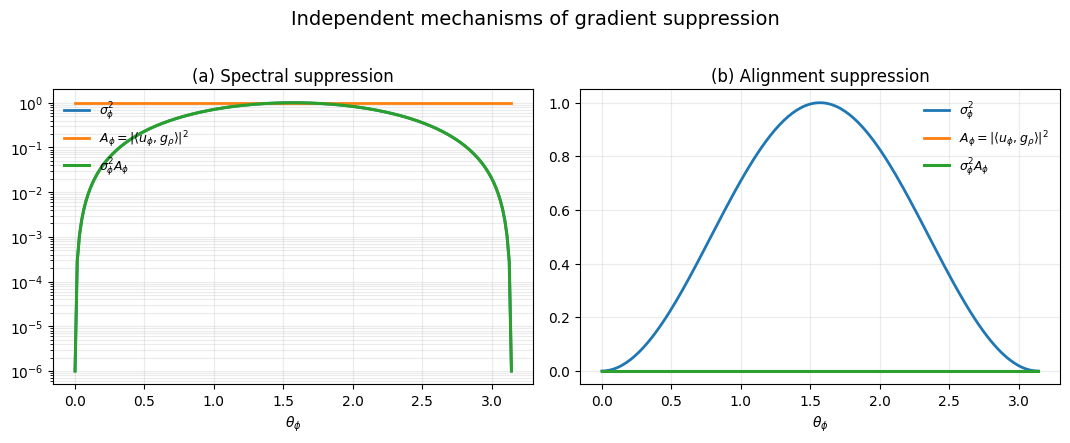

'figures_jacobian_qfim\\fig_validationI_suppression_mechanisms.pdf'

In [10]:
def plot_validation_I(
    df: pd.DataFrame,
    filename: str = "fig_validationI_suppression_mechanisms.pdf",
):
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.3))

    spectral = df[df["mechanism"] == "spectral_X_phi0"]
    alignment = df[df["mechanism"] == "alignment_Z_phi07"]

    # ==========================================================
    # (a) Spectral suppression
    # ==========================================================
    ax = axes[0]

    ax.plot(
        spectral["theta"],
        spectral["sigma2_mode2"],
        linewidth=2.0,
        label=r"$\sigma_\phi^2$",
    )

    ax.plot(
        spectral["theta"],
        spectral["align_mode2"],
        linewidth=2.0,
        label=r"$A_\phi = |\langle u_\phi,g_\rho\rangle|^2$",
    )

    ax.plot(
        spectral["theta"],
        spectral["contrib_mode2"],
        linewidth=2.2,
        label=r"$\sigma_\phi^2A_\phi$",
    )

    ax.set_yscale("log")
    ax.set_xlabel(r"$\theta_\phi$")
    ax.set_title("(a) Spectral suppression")
    ax.grid(True, which="both", alpha=0.25)

    ax.legend(
        frameon=False,
        loc="upper left",
        fontsize=9,
    )

    # ==========================================================
    # (b) Alignment suppression
    # ==========================================================
    ax = axes[1]

    ax.plot(
        alignment["theta"],
        alignment["sigma2_mode2"],
        linewidth=2.0,
        label=r"$\sigma_\phi^2$",
    )

    ax.plot(
        alignment["theta"],
        alignment["align_mode2"],
        linewidth=2.0,
        label=r"$A_\phi = |\langle u_\phi,g_\rho\rangle|^2$",
    )

    ax.plot(
        alignment["theta"],
        alignment["contrib_mode2"],
        linewidth=2.2,
        label=r"$\sigma_\phi^2A_\phi$",
    )

    ax.set_xlabel(r"$\theta_\phi$")
    ax.set_title("(b) Alignment suppression")
    ax.grid(True, alpha=0.25)

    ax.legend(
        frameon=False,
        loc="upper right",
        fontsize=9,
    )

    fig.suptitle(
        "Independent mechanisms of gradient suppression",
        y=1.02,
        fontsize=14,
    )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(
        path,
        bbox_inches="tight",
    )

    fig.savefig(
        path.replace(".pdf", ".png"),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    return path


plot_validation_I(valI_df)

# Validation II — same DLA, different Jacobian geometry

In [11]:
def compare_pair(ansA: AnsatzSpec, ansB: AnsatzSpec, thetaA: np.ndarray, thetaB: np.ndarray, obs: SparsePauliOp, eps: float = 1e-6) -> Dict:
    dA = modal_diagnostics(ansA, thetaA, obs, eps=eps)
    dB = modal_diagnostics(ansB, thetaB, obs, eps=eps)
    return {
        "name_A": ansA.name,
        "name_B": ansB.name,
        "same_generator_labels": set(ansA.generator_labels) == set(ansB.generator_labels),
        "rank_A": dA["rank_eps"],
        "rank_B": dB["rank_eps"],
        "sigma_max_A": dA["sigma_max"],
        "sigma_max_B": dB["sigma_max"],
        "spec_sum_A": dA["spec_sum"],
        "spec_sum_B": dB["spec_sum"],
        "grad_norm2_A": dA["grad_norm2"],
        "grad_norm2_B": dB["grad_norm2"],
    }

# One- and two-qubit direct checks
ans1A, ans1B = single_qubit_A(), single_qubit_B()
ans2A, ans2B = two_qubit_A(), two_qubit_B()

pair_rows = []
pair_rows.append(compare_pair(ans1A, ans1B, np.array([0.8, 1.1]), np.array([0.8, 1.1]), make_observable("X")))
pair_rows.append(compare_pair(ans2A, ans2B, np.array([0.8, 1.1]), np.array([0.8, 1.1]), make_observable("XI")))
pd.DataFrame(pair_rows)

,name_A,name_B,same_generator_labels,rank_A,rank_B,sigma_max_A,sigma_max_B,spec_sum_A,spec_sum_B,grad_norm2_A,grad_norm2_B
0,1q_A_RZ_after_RX,1q_B_RX_after_RZ,True,2,1,1.0,1.0,1.5146,1.0,0.491408,7.703720e-22
1,2q_A_RZ_after_RXX,2q_B_RXX_after_RZ,True,2,1,1.0,1.0,1.5146,1.0,0.000000,0.000000e+00


In [12]:
def validation_II_scaling(
    ns=(2,3,4,5,6,7,8,10),
    layers: int = 1,
    n_samples: int = 150,
    seed: int = 20,
    eps: float = 1e-6,
    observable_builder: Callable[[int], SparsePauliOp] = nearest_neighbor_yx_observable,
    observable_name: str = "nearest_neighbor_YX",
) -> pd.DataFrame:
    """Scaling test for DLA-equivalent A/B chain families.

    The same random parameter vector is used for A and B at each (n, sample)
    whenever both ansätze have the same number of parameters. This makes the
    comparison paired rather than merely distributional.

    Panel C of the corresponding paper figure uses grad_norm2 with the
    phase-sensitive observable chosen by `observable_builder`.
    """
    local_rng = np.random.default_rng(seed)
    rows = []

    for n in ns:
        obs = observable_builder(n)
        builders = [
            ("A_entangle_then_RZ", dla_equiv_chain_A),
            ("B_RZ_then_entangle", dla_equiv_chain_B),
        ]

        # A and B have the same number of parameters by construction.
        p_ref = builders[0][1](n, layers).n_params

        for s in range(n_samples):
            theta_shared = local_rng.uniform(-np.pi, np.pi, size=p_ref)

            for family_name, builder in builders:
                ans = builder(n, layers)
                theta = theta_shared if ans.n_params == p_ref else local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
                diag = modal_diagnostics(ans, theta, obs, eps=eps)
                rows.append({
                    "n": n,
                    "layers": layers,
                    "family": family_name,
                    "sample": s,
                    "observable": observable_name,
                    "p": ans.n_params,
                    "same_generator_set": True,
                    "rank_eps": diag["rank_eps"],
                    "sigma_max": diag["sigma_max"],
                    "spec_sum": diag["spec_sum"],
                    "align_sum": diag["align_sum"],
                    "grad_norm2": diag["grad_norm2"],
                    "recon_norm2": diag["recon_norm2"],
                    "rel_error": diag["rel_error"],
                })

    return pd.DataFrame(rows)


# Main paper-style dataset for Validation II.
# v3 production-style run for the A/B scaling figure.
# Keep layers=1 here to isolate ordering effects cleanly; use n up to 8.
valII_df = validation_II_scaling(ns=(2,3,4,5,6,7,8), layers=1, n_samples=150)
valII_df.groupby(["n", "family"])[["rank_eps", "spec_sum", "grad_norm2", "align_sum"]].mean().head(12)


rank_eps   spec_sum  grad_norm2  align_sum
n family                                                        
2 A_entangle_then_RZ       2.0   2.062632    0.807053   0.753585
  B_RZ_then_entangle       1.0   1.000000    0.498100   0.498100
3 A_entangle_then_RZ       5.0   3.757607    0.285988   0.366380
  B_RZ_then_entangle       2.0   2.000000    0.256136   0.256136
4 A_entangle_then_RZ       7.0   5.413403    0.188655   0.221339
  B_RZ_then_entangle       3.0   3.000000    0.162557   0.162557
5 A_entangle_then_RZ       9.0   7.312128    0.143159   0.159184
  B_RZ_then_entangle       4.0   4.000000    0.124884   0.124884
6 A_entangle_then_RZ      11.0   9.059154    0.116048   0.127695
  B_RZ_then_entangle       5.0   5.000000    0.099912   0.099912
7 A_entangle_then_RZ      13.0  10.740996    0.093037   0.104573
  B_RZ_then_entangle       6.0   6.000000    0.086898   0.086898

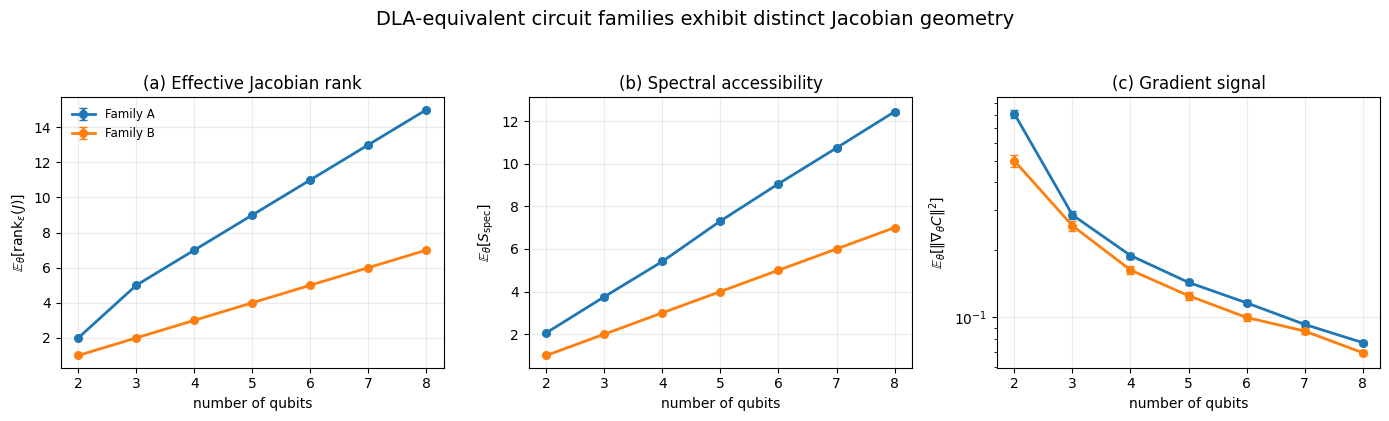

'figures_jacobian_qfim\\fig_validationII_dla_same_jacobian_different.pdf'

In [13]:
def plot_validation_II_scaling(
    df: pd.DataFrame,
    filename: str = "fig_validationII_dla_same_jacobian_different.pdf",
    use_sem: bool = True,
):
    grouped = df.groupby(["n", "family"])

    agg = grouped.agg(
        rank_mean=("rank_eps", "mean"),
        rank_std=("rank_eps", "std"),
        spec_mean=("spec_sum", "mean"),
        spec_std=("spec_sum", "std"),
        grad_mean=("grad_norm2", "mean"),
        grad_std=("grad_norm2", "std"),
        n_samples=("sample", "count"),
    ).reset_index()

    if use_sem:
        for prefix in ["rank", "spec", "grad"]:
            agg[f"{prefix}_err"] = (
                agg[f"{prefix}_std"].fillna(0)
                / np.sqrt(agg["n_samples"].clip(lower=1))
            )
    else:
        for prefix in ["rank", "spec", "grad"]:
            agg[f"{prefix}_err"] = agg[f"{prefix}_std"].fillna(0)

    family_labels = {
        "A_entangle_then_RZ": "Family A",
        "B_RZ_then_entangle": "Family B",
    }

    fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.0))

    metrics = [
        (
            "rank_mean",
            "rank_err",
            r"$\mathbb{E}_\theta[\mathrm{rank}_\epsilon(J)]$",
            "(a) Effective Jacobian rank",
        ),
        (
            "spec_mean",
            "spec_err",
            r"$\mathbb{E}_\theta[S_{\mathrm{spec}}]$",
            "(b) Spectral accessibility",
        ),
        (
            "grad_mean",
            "grad_err",
            r"$\mathbb{E}_\theta[\|\nabla_\theta C\|^2]$",
            "(c) Gradient signal",
        ),
    ]

    for ax, (m, err, ylabel, title) in zip(axes, metrics):
        for fam in sorted(agg["family"].unique()):
            sub = agg[agg["family"] == fam].sort_values("n")

            ax.errorbar(
                sub["n"],
                sub[m],
                yerr=sub[err],
                marker="o",
                capsize=3,
                linewidth=2.0,
                markersize=5.5,
                label=family_labels.get(fam, fam),
            )

        ax.set_xlabel("number of qubits")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.25)

    if np.all(agg["grad_mean"].values > 0):
        axes[2].set_yscale("log")

    axes[0].legend(
        frameon=False,
        fontsize=8.5,
        loc="upper left",
    )

    fig.suptitle(
        "DLA-equivalent circuit families exhibit distinct Jacobian geometry",
        fontsize=14,
        y=1.04,
    )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(
        path,
        bbox_inches="tight",
    )

    fig.savefig(
        path.replace(".pdf", ".png"),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    return path


plot_validation_II_scaling(valII_df)

In [14]:
def validation_II_permutation_distribution(
    n: int = 6,
    layers: int = 2,
    n_perms: int = 200,
    seed: int = 30,
    eps: float = 1e-6,
    observable_builder: Callable[[int], SparsePauliOp] = nearest_neighbor_yx_observable,
    observable_name: str = "nearest_neighbor_YX",
) -> pd.DataFrame:
    base = dla_equiv_chain_A(n, layers)
    obs = observable_builder(n)
    rows = []

    for s in range(n_perms):
        ans = random_permutation_same_generators(base, seed=seed+s)
        theta = np.random.default_rng(seed+1000+s).uniform(-np.pi, np.pi, size=ans.n_params)
        diag = modal_diagnostics(ans, theta, obs, eps=eps)
        rows.append({
            "perm": s,
            "n": n,
            "layers": layers,
            "observable": observable_name,
            "rank_eps": diag["rank_eps"],
            "sigma_max": diag["sigma_max"],
            "spec_sum": diag["spec_sum"],
            "align_sum": diag["align_sum"],
            "grad_norm2": diag["grad_norm2"],
        })
    return pd.DataFrame(rows)


perm_df = validation_II_permutation_distribution(n=6, layers=2, n_perms=200)
perm_df.describe()


,perm,n,layers,rank_eps,sigma_max,spec_sum,align_sum,grad_norm2
count,200.000000,200.0,200.0,200.000000,200.000000,200.000000,200.000000,200.000000
mean,99.500000,6.0,2.0,12.530000,1.602754,15.125643,0.123046,0.169990
std,57.879185,0.0,0.0,2.024746,0.150244,1.762741,0.032232,0.060035
min,0.000000,6.0,2.0,8.000000,1.414214,10.879489,0.048234,0.046295
25%,49.750000,6.0,2.0,11.000000,1.478293,13.792453,0.095813,0.129441
50%,99.500000,6.0,2.0,13.000000,1.588932,15.224945,0.123674,0.163130
75%,149.250000,6.0,2.0,14.000000,1.692529,16.281922,0.149085,0.206027
max,199.000000,6.0,2.0,19.000000,1.994417,21.354406,0.200867,0.371968


'figures_jacobian_qfim\\fig_validationII_permutation_distribution.pdf'

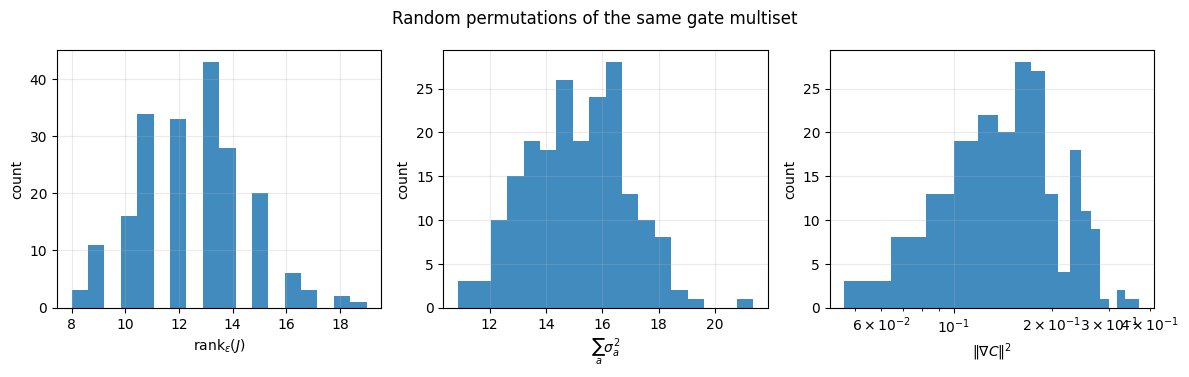

In [15]:
def plot_permutation_distribution(df: pd.DataFrame, filename: str = "fig_validationII_permutation_distribution.pdf"):
    fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8))
    for ax, col, xlabel in zip(
        axes,
        ["rank_eps", "spec_sum", "grad_norm2"],
        [r"$\mathrm{rank}_\epsilon(J)$", r"$\sum_a\sigma_a^2$", r"$\|\nabla C\|^2$"]
    ):
        ax.hist(df[col], bins=18, alpha=0.85)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("count")
        ax.grid(True, alpha=0.25)
        if col == "grad_norm2":
            ax.set_xscale("log")
    fig.suptitle("Random permutations of the same gate multiset")
    fig.tight_layout()
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    return path

plot_permutation_distribution(perm_df)

Spectral accessibility vs gradient
Pearson r = 0.1812, p = 1.02e-02
Spearman rho = 0.1221, p = 8.50e-02

Task alignment vs gradient
Pearson r = 0.7352, p = 2.82e-35
Spearman rho = 0.7374, p = 1.40e-35

Joint modal contribution vs gradient
Pearson r = 0.7112, p = 3.96e-32
Spearman rho = 0.7018, p = 5.46e-31


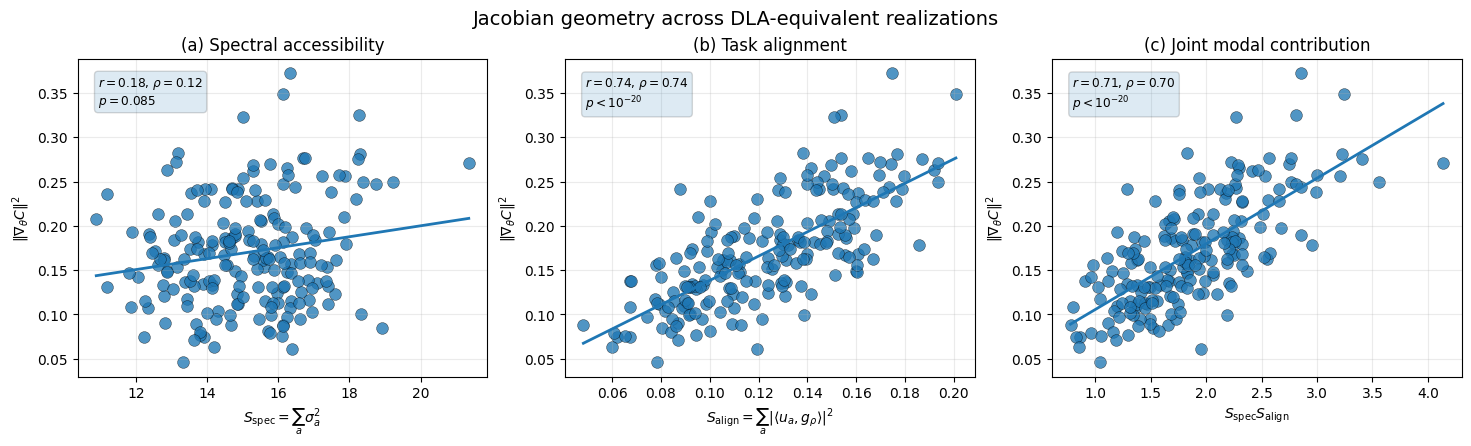

Saved:
figures_jacobian_qfim\fig_validationII_jacobian_geometry_permutations.pdf
figures_jacobian_qfim\fig_validationII_jacobian_geometry_permutations.png


In [16]:
# ==========================================================
# Jacobian geometry across DLA-equivalent realizations
# Paper-ready version without shared colorbar
# ==========================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import os

df = perm_df.copy()

spec = df["spec_sum"].to_numpy()
align = df["align_sum"].to_numpy()
grad = df["grad_norm2"].to_numpy()

combined = spec * align


def corr_text(x, y):
    r, p = pearsonr(x, y)
    rho, ps = spearmanr(x, y)
    return r, p, rho, ps


def format_p(p):
    if p < 1e-20:
        return r"$p<10^{-20}$"
    if p < 1e-3:
        return rf"$p={p:.1e}$"
    return rf"$p={p:.3f}$"


r_spec, p_spec, rho_spec, ps_spec = corr_text(spec, grad)
r_align, p_align, rho_align, ps_align = corr_text(align, grad)
r_comb, p_comb, rho_comb, ps_comb = corr_text(combined, grad)

print("Spectral accessibility vs gradient")
print(f"Pearson r = {r_spec:.4f}, p = {p_spec:.2e}")
print(f"Spearman rho = {rho_spec:.4f}, p = {ps_spec:.2e}")

print("\nTask alignment vs gradient")
print(f"Pearson r = {r_align:.4f}, p = {p_align:.2e}")
print(f"Spearman rho = {rho_align:.4f}, p = {ps_align:.2e}")

print("\nJoint modal contribution vs gradient")
print(f"Pearson r = {r_comb:.4f}, p = {p_comb:.2e}")
print(f"Spearman rho = {rho_comb:.4f}, p = {ps_comb:.2e}")


fig, axes = plt.subplots(
    1,
    3,
    figsize=(14.6, 4.35),
    constrained_layout=True,
)

panels = [
    (
        axes[0],
        spec,
        grad,
        r"$S_{\mathrm{spec}}=\sum_a\sigma_a^2$",
        "(a) Spectral accessibility",
        r_spec,
        p_spec,
        rho_spec,
        ps_spec,
    ),
    (
        axes[1],
        align,
        grad,
        r"$S_{\mathrm{align}}=\sum_a |\langle u_a,g_\rho\rangle|^2$",
        "(b) Task alignment",
        r_align,
        p_align,
        rho_align,
        ps_align,
    ),
    (
        axes[2],
        combined,
        grad,
        r"$S_{\mathrm{spec}}S_{\mathrm{align}}$",
        "(c) Joint modal contribution",
        r_comb,
        p_comb,
        rho_comb,
        ps_comb,
    ),
]

for ax, x, y, xlabel, title, r_val, p_val, rho_val, ps_val in panels:

    ax.scatter(
        x,
        y,
        s=72,
        alpha=0.78,
        edgecolors="k",
        linewidths=0.30,
    )

    coef = np.polyfit(x, y, 1)
    xx = np.linspace(x.min(), x.max(), 150)

    ax.plot(
        xx,
        coef[0] * xx + coef[1],
        "-",
        linewidth=2.0,
    )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"$\|\nabla_\theta C\|^2$")
    ax.set_title(title)
    ax.grid(True, alpha=0.25)

    ax.text(
        0.05,
        0.95,
        (
            rf"$r={r_val:.2f}$, $\rho={rho_val:.2f}$" "\n"
            rf"{format_p(ps_val)}"
        ),
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.7,
        bbox=dict(
            boxstyle="round",
            alpha=0.15,
        ),
    )

fig.suptitle(
    "Jacobian geometry across DLA-equivalent realizations",
    fontsize=14,
)

path_pdf = os.path.join(
    FIG_DIR,
    "fig_validationII_jacobian_geometry_permutations.pdf",
)

path_png = path_pdf.replace(".pdf", ".png")

fig.savefig(
    path_pdf,
    bbox_inches="tight",
)

fig.savefig(
    path_png,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved:")
print(path_pdf)
print(path_png)

# Validation III — scaling with qubits, depth and cost locality

In [17]:
def validation_III_scaling(
    ns=(2,4,6,8,10),
    depths=(2,3,4),
    families=("hea", "local", "chainA", "chainB"),
    n_samples: int = 50,
    seed: int = 40,
    eps: float = 1e-6,
    include_symmetry_control: bool = False,
) -> pd.DataFrame:
    """Scaling diagnostics for gradient, spectral energy and alignment.

    v2 changes:
    - uses the Hilbert--Schmidt metric convention (METRIC_SCALE=4);
    - replaces the chainA/chainB global_Z task by a symmetry-breaking global
      mixed Pauli string, so vanishing gradients are not caused by an exact
      commutation symmetry;
    - optionally includes global_Z as a symmetry-control task.
    """
    local_rng = np.random.default_rng(seed)
    rows = []
    for n in ns:
        for L in depths:
            for fam in families:
                if fam == "hea":
                    ans = hea_ansatz(n, L, entangler="rzz")
                elif fam == "local":
                    ans = local_rxrz_ansatz(n, L)
                elif fam == "chainA":
                    ans = dla_equiv_chain_A(n, L)
                elif fam == "chainB":
                    ans = dla_equiv_chain_B(n, L)
                else:
                    raise ValueError(fam)

                observables = {
                    "local_Z1": local_Z(n, 0),
                    "global_mixed": global_mixed_phase_string(n),
                }
                if include_symmetry_control:
                    observables["global_Z_symmetry_control"] = global_Z(n)

                for cost_name, obs in observables.items():
                    for s in range(n_samples):
                        theta = local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
                        diag = modal_diagnostics(ans, theta, obs, eps=eps)
                        rows.append({
                            "n": n,
                            "depth": L,
                            "family": fam,
                            "cost": cost_name,
                            "sample": s,
                            "p": ans.n_params,
                            "grad_norm2": diag["grad_norm2"],
                            "spec_sum": diag["spec_sum"],
                            "align_sum": diag["align_sum"],
                            "sigma_max": diag["sigma_max"],
                            "rank_eps": diag["rank_eps"],
                            "sigma_min_pos": diag["sigma_min_pos"],
                            "active_n": diag["active_n"],
                            "active_sigma2_min": diag["active_sigma2_min"],
                            "active_sigma2_max": diag["active_sigma2_max"],
                            "active_sigma2_ratio": diag["active_sigma2_ratio"],
                            "active_sigma2_logspread": diag["active_sigma2_logspread"],
                        })
    return pd.DataFrame(rows)

# v3 production-oriented default.
# Larger qubit/depth sweep for final figures. This is heavier than v2.
valIII_df = validation_III_scaling(ns=(2,4,6,8,10), depths=(2,3,4), n_samples=50)
valIII_df.head()


,n,depth,family,cost,sample,p,grad_norm2,spec_sum,align_sum,sigma_max,rank_eps,sigma_min_pos,active_n,active_sigma2_min,active_sigma2_max,active_sigma2_ratio,active_sigma2_logspread
0,2,2,hea,local_Z1,0,10,1.283166,8.378071,0.698306,1.725195,6,0.389300,6,0.151554,2.976298,19.638476,1.293108
1,2,2,hea,local_Z1,1,10,0.630832,6.927084,0.529945,1.506956,6,0.324717,6,0.105441,2.270917,21.537261,1.333190
2,2,2,hea,local_Z1,2,10,0.757210,7.203187,0.660505,1.550521,6,0.168633,6,0.028437,2.404115,84.541345,1.927069
3,2,2,hea,local_Z1,3,10,1.017889,8.153806,0.992465,1.436317,6,0.710734,6,0.505143,2.063006,4.084004,0.611086
4,2,2,hea,local_Z1,4,10,0.679304,8.180246,0.673299,1.680273,6,0.667218,6,0.445180,2.823319,6.341974,0.802224


In [18]:
def aggregate_scaling(df: pd.DataFrame) -> pd.DataFrame:
    return df.groupby(["n", "depth", "family", "cost"]).agg(
        grad_mean=("grad_norm2", "mean"), grad_sem=("grad_norm2", lambda x: x.std(ddof=1)/np.sqrt(len(x))),
        spec_mean=("spec_sum", "mean"), spec_sem=("spec_sum", lambda x: x.std(ddof=1)/np.sqrt(len(x))),
        align_mean=("align_sum", "mean"), align_sem=("align_sum", lambda x: x.std(ddof=1)/np.sqrt(len(x))),
        sigma_max_mean=("sigma_max", "mean"),
        rank_mean=("rank_eps", "mean"),
    ).reset_index()

valIII_agg = aggregate_scaling(valIII_df)
valIII_agg.head()

,n,depth,family,cost,grad_mean,grad_sem,spec_mean,spec_sem,align_mean,align_sem,sigma_max_mean,rank_mean
0,2,2,chainA,global_mixed,1.565981,0.131901,4.177254,0.117992,0.662500,0.042241,1.637305,2.0
1,2,2,chainA,local_Z1,0.983985,0.084527,4.014602,0.133211,0.615348,0.047441,1.608509,2.0
2,2,2,chainB,global_mixed,0.990824,0.079611,2.676769,0.069201,0.627762,0.043661,1.323647,2.0
3,2,2,chainB,local_Z1,0.992272,0.071116,2.684340,0.081862,0.650577,0.043017,1.315589,2.0
4,2,2,hea,global_mixed,0.864776,0.063222,7.824130,0.114626,0.840219,0.026274,1.606017,6.0


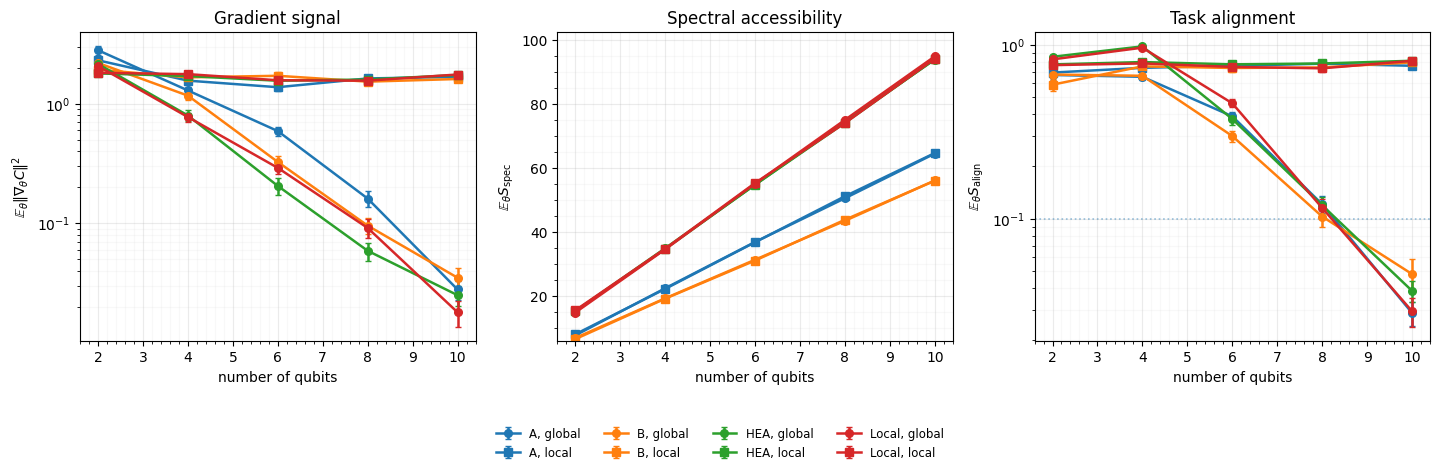

Saved:
figures_jacobian_qfim\fig_validationIII_scaling_local_global_v4.pdf


In [19]:
def plot_validation_III_scaling(
    df: pd.DataFrame,
    depth: int = 4,
    filename: str = "fig_validationIII_scaling_local_global_v4.pdf",
):
    agg = aggregate_scaling(df)
    agg = agg[agg["depth"] == depth].copy()

    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))

    metrics = [
        (
            "grad_mean",
            "grad_sem",
            r"$\mathbb{E}_\theta\|\nabla_\theta C\|^2$",
            "log",
            "Gradient signal",
        ),
        (
            "spec_mean",
            "spec_sem",
            r"$\mathbb{E}_\theta S_{\mathrm{spec}}$",
            "linear",
            "Spectral accessibility",
        ),
        (
            "align_mean",
            "align_sem",
            r"$\mathbb{E}_\theta S_{\mathrm{align}}$",
            "log",
            "Task alignment",
        ),
    ]

    family_labels = {
        "chainA": "A",
        "chainB": "B",
        "hea": "HEA",
        "local": "Local",
    }

    cost_labels = {
        "global_mixed": "global",
        "local_Z1": "local",
        "global_Z": "global Z",
        "global_Z_symmetry_control": "global Z control",
        "nearest_neighbor_YX": "nearest-neighbor",
        "phase": "phase",
    }

    family_colors = {
        "chainA": "C0",
        "chainB": "C1",
        "hea": "C2",
        "local": "C3",
    }

    cost_markers = {
        "global_mixed": "o",
        "local_Z1": "s",
        "global_Z": "o",
        "global_Z_symmetry_control": "x",
        "nearest_neighbor_YX": "^",
        "phase": "D",
    }

    legend_handles = []
    legend_labels = []

    for ax, (m, sem, ylabel, scale, title) in zip(axes, metrics):
        for fam in sorted(agg["family"].unique()):
            for cost in sorted(agg["cost"].unique()):
                sub = agg[
                    (agg["family"] == fam)
                    & (agg["cost"] == cost)
                ].sort_values("n")

                if len(sub) == 0:
                    continue

                color = family_colors.get(fam, None)
                marker = cost_markers.get(cost, "o")

                label = (
                    f"{family_labels.get(fam, fam)}, "
                    f"{cost_labels.get(cost, cost)}"
                )

                eb = ax.errorbar(
                    sub["n"],
                    sub[m],
                    yerr=sub[sem].fillna(0),
                    marker=marker,
                    color=color,
                    capsize=2.5,
                    linewidth=1.8,
                    markersize=5.5,
                    label=label,
                )

                if m == "grad_mean":
                    legend_handles.append(eb)
                    legend_labels.append(label)

        ax.set_xlabel("number of qubits")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.set_yscale(scale)

        ax.minorticks_on()
        ax.grid(True, which="major", alpha=0.25)
        ax.grid(True, which="minor", alpha=0.08)

        if m == "spec_mean":
            y_values = agg[m].replace([np.inf, -np.inf], np.nan).dropna()
            y_values = y_values[y_values > 0]

            if len(y_values) > 0:
                ymin = max(0.0, 0.90 * y_values.min())
                ymax = 1.08 * y_values.max()
                ax.set_ylim(ymin, ymax)

        if m == "align_mean":
            ax.axhline(
                1e-1,
                linestyle=":",
                linewidth=1.2,
                alpha=0.45,
            )

    fig.legend(
        legend_handles,
        legend_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.08),
        ncol=4,
        frameon=False,
        fontsize=8.5,
    )

    fig.tight_layout(rect=(0, 0.08, 1, 1))

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(
        path,
        bbox_inches="tight",
    )

    fig.savefig(
        path.replace(".pdf", ".png"),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    return path


path_scaling = plot_validation_III_scaling(
    valIII_df,
    depth=4,
)

print("Saved:")
print(path_scaling)

# Validation IV — predictive value for actual training

In [20]:
def gradient_descent_train(
    ansatz: AnsatzSpec,
    theta0: np.ndarray,
    observable: SparsePauliOp,
    target: float = -1.0,
    lr: float = 0.08,
    steps: int = 100,
    eps: float = 1e-6,
    threshold: float = 1e-3,
) -> Dict:
    # Loss = 0.5*(C(theta)-target)^2
    theta = theta0.copy()
    history = []
    hit_iter = None
    for t in range(steps):
        c = cost_value(ansatz, theta, observable)
        loss = 0.5*(c - target)**2
        history.append(loss)
        if hit_iter is None and loss < threshold:
            hit_iter = t
        grad_C = finite_difference_gradient(ansatz, theta, observable, eps=eps)
        grad_loss = (c - target) * grad_C
        theta = theta - lr * grad_loss
    c = cost_value(ansatz, theta, observable)
    final_loss = 0.5*(c - target)**2
    if hit_iter is None and final_loss < threshold:
        hit_iter = steps
    return {
        "theta_final": theta,
        "final_cost": c,
        "final_loss": float(final_loss),
        "hit_iter": hit_iter if hit_iter is not None else np.nan,
        "success": bool(final_loss < threshold),
        "history": np.array(history),
    }


def validation_IV_predictive(
    n_instances: int = 200,
    n: int = 6,
    depth: int = 4,
    seed: int = 50,
    eps: float = 1e-6,
) -> pd.DataFrame:
    """Predictive validation at nontrivial depth.

    v3 uses n=6, depth=4 by default to avoid the shallow regime where all
    gradient-active modes have the same canonical singular value. It also uses
    a symmetry-breaking global observable instead of global_Z for chain families.
    """
    local_rng = np.random.default_rng(seed)
    rows = []
    family_builders = {
        "hea": lambda: hea_ansatz(n, depth, entangler="rzz"),
        "local": lambda: local_rxrz_ansatz(n, depth),
        "chainA": lambda: dla_equiv_chain_A(n, depth),
        "chainB": lambda: dla_equiv_chain_B(n, depth),
    }
    for s in range(n_instances):
        fam = local_rng.choice(list(family_builders.keys()))
        ans = family_builders[fam]()

        if local_rng.random() < 0.5:
            obs = local_Z(n, 0)
            cost_name = "local_Z1"
        else:
            obs = global_mixed_phase_string(n)
            cost_name = "global_mixed"

        theta0 = local_rng.uniform(-np.pi, np.pi, size=ans.n_params)
        diag0 = modal_diagnostics(ans, theta0, obs, eps=eps)
        train = gradient_descent_train(ans, theta0, obs, target=-1.0, lr=0.08, steps=100, eps=eps, threshold=1e-3)
        rows.append({
            "instance": s,
            "family": fam,
            "cost": cost_name,
            "n": n,
            "depth": depth,
            "p": ans.n_params,
            "init_grad_norm2": diag0["grad_norm2"],
            "init_sigma_max": diag0["sigma_max"],
            "init_spec_sum": diag0["spec_sum"],
            "init_align_sum": diag0["align_sum"],
            "init_rank_eps": diag0["rank_eps"],
            "active_n": diag0["active_n"],
            "active_sigma2_min": diag0["active_sigma2_min"],
            "active_sigma2_max": diag0["active_sigma2_max"],
            "active_sigma2_ratio": diag0["active_sigma2_ratio"],
            "active_sigma2_logspread": diag0["active_sigma2_logspread"],
            "final_loss": train["final_loss"],
            "success": train["success"],
            "hit_iter": train["hit_iter"],
        })
    return pd.DataFrame(rows)

valIV_df = validation_IV_predictive(n_instances=200, n=6, depth=4)
valIV_df.head()


,instance,family,cost,n,depth,p,init_grad_norm2,init_sigma_max,init_spec_sum,init_align_sum,init_rank_eps,active_n,active_sigma2_min,active_sigma2_max,active_sigma2_ratio,active_sigma2_logspread,final_loss,success,hit_iter
0,0,chainB,global_mixed,6,4,44,0.066590,2.047873,32.808522,0.095366,30,29,0.000007,4.193783,5.722756e+05,5.757605,0.008055,False,NaN
1,1,chainB,local_Z1,6,4,44,0.811227,1.960895,28.778128,0.357991,29,22,0.003484,3.845109,1.103680e+03,3.042843,0.000274,True,52.0
2,2,local,local_Z1,6,4,68,1.513716,2.492807,55.052229,0.617923,64,38,0.001472,6.214086,4.222705e+03,3.625591,0.002082,False,NaN
3,3,chainB,local_Z1,6,4,44,1.430068,1.878117,34.137683,0.952505,30,27,0.017839,3.527323,1.977310e+02,2.296075,0.001654,False,NaN
4,4,hea,global_mixed,6,4,68,0.532571,2.580254,55.981248,0.679618,64,60,0.000002,6.657711,3.220922e+06,6.507980,0.004548,False,NaN


In [21]:
# Diagnostic required in v2:
# confirm that the gradient-active singular values are not all identical.
# If active_sigma2_logspread is near zero for most rows, the experiment is
# effectively testing alignment only.

def summarize_active_spectrum(df: pd.DataFrame) -> pd.DataFrame:
    cols = [
        "active_n",
        "active_sigma2_min",
        "active_sigma2_max",
        "active_sigma2_ratio",
        "active_sigma2_logspread",
    ]
    summary = df[cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    return summary

active_summary_IV = summarize_active_spectrum(valIV_df)
display(active_summary_IV)

print("Median active sigma^2 log-spread:", np.nanmedian(valIV_df["active_sigma2_logspread"]))
print("Fraction with active log-spread > 0.25:", np.mean(valIV_df["active_sigma2_logspread"] > 0.25))


,active_n,active_sigma2_min,active_sigma2_max,active_sigma2_ratio,active_sigma2_logspread
count,200.000000,2.000000e+02,200.000000,2.000000e+02,200.000000
mean,37.085000,3.347321e-03,5.285052,2.769584e+07,4.691037
std,12.305482,1.322270e-02,1.288799,1.800243e+08,1.758521
min,17.000000,3.804774e-09,3.190036,3.182273e+01,1.502737
10%,25.000000,4.169794e-07,3.679852,6.920877e+02,2.840160
25%,28.000000,3.112330e-06,4.192685,1.782806e+03,3.250978
50%,30.000000,5.194199e-04,5.245945,8.651792e+03,3.936220
75%,46.250000,2.859294e-03,6.196420,1.600413e+06,6.204174
90%,58.000000,7.066286e-03,6.961259,1.236072e+07,7.091322
max,63.000000,1.728856e-01,8.613884,2.088346e+09,9.319802


Median active sigma^2 log-spread: 3.9362195166208185
Fraction with active log-spread > 0.25: 1.0


In [22]:
def correlation_table(df: pd.DataFrame, predictors: Sequence[str], target: str = "final_loss") -> pd.DataFrame:
    rows = []
    for p in predictors:
        pearson = df[[p, target]].corr(method="pearson").iloc[0, 1]
        spearman = df[[p, target]].corr(method="spearman").iloc[0, 1]
        rows.append({"predictor": p, "target": target, "pearson": pearson, "spearman": spearman})
    return pd.DataFrame(rows)

pred_cols = ["init_grad_norm2", "init_sigma_max", "init_spec_sum", "init_align_sum", "init_rank_eps"]
correlation_table(valIV_df, pred_cols, target="final_loss")

,predictor,target,pearson,spearman
0,init_grad_norm2,final_loss,-0.110938,-0.691702
1,init_sigma_max,final_loss,0.106076,-0.047794
2,init_spec_sum,final_loss,0.026137,-0.001259
3,init_align_sum,final_loss,-0.079181,-0.478098
4,init_rank_eps,final_loss,0.075922,0.018575


'figures_jacobian_qfim\\fig_validationIV_predictive_training.pdf'

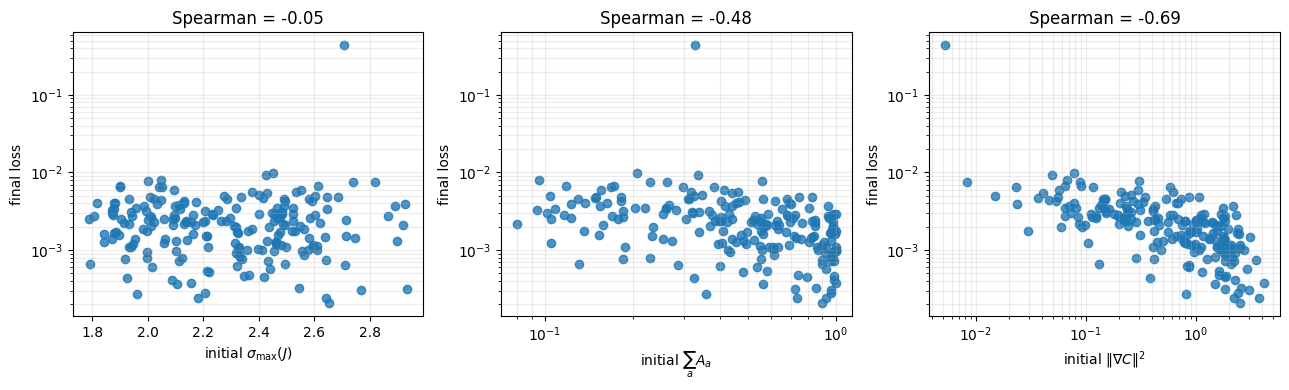

In [23]:
def plot_validation_IV_predictive(df: pd.DataFrame, filename: str = "fig_validationIV_predictive_training.pdf"):
    fig, axes = plt.subplots(1, 3, figsize=(13.0, 4.0))
    panels = [
        ("init_sigma_max", r"initial $\sigma_{\max}(J)$"),
        ("init_align_sum", r"initial $\sum_a A_a$"),
        ("init_grad_norm2", r"initial $\|\nabla C\|^2$"),
    ]
    for ax, (col, xlabel) in zip(axes, panels):
        ax.scatter(df[col], df["final_loss"], s=36, alpha=0.8)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("final loss")
        ax.set_yscale("log")
        if col != "init_sigma_max":
            ax.set_xscale("log")
        ax.grid(True, which="both", alpha=0.25)
        sp = df[[col, "final_loss"]].corr(method="spearman").iloc[0, 1]
        ax.set_title(f"Spearman = {sp:.2f}")
    fig.tight_layout()
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    return path

plot_validation_IV_predictive(valIV_df)

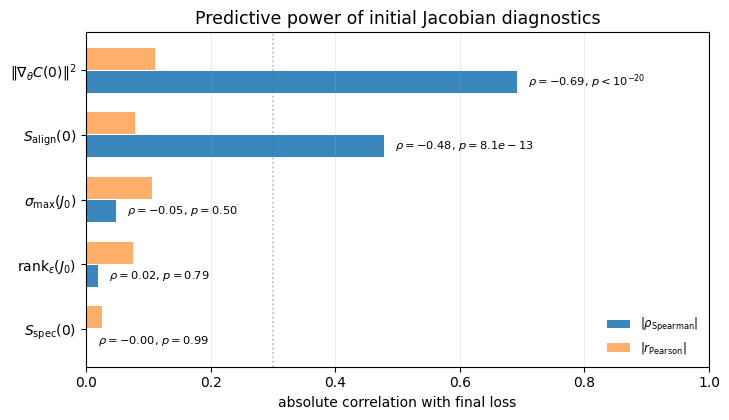

,predictor,pearson,pearson_p,spearman,spearman_p
2,init_spec_sum,0.026137,0.713336,-0.001259,9.858887e-01
3,init_rank_eps,0.075922,0.285289,0.018575,7.940455e-01
4,init_sigma_max,0.106076,0.134927,-0.047794,5.015458e-01
1,init_align_sum,-0.079181,0.265055,-0.478098,8.098905e-13
0,init_grad_norm2,-0.110938,0.117843,-0.691702,8.375106e-30


Saved:
figures_jacobian_qfim\fig_validationIV_predictor_ranking_v4.pdf


In [24]:
# ==========================================================
# Validation IV — predictor ranking by absolute correlation
# ==========================================================

from scipy.stats import pearsonr, spearmanr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os


def validation_IV_predictor_ranking(
    df: pd.DataFrame,
    target: str = "final_loss",
    filename: str = "fig_validationIV_predictor_ranking_v4.pdf",
):
    predictors = [
        ("init_grad_norm2", r"$\|\nabla_\theta C(0)\|^2$"),
        ("init_align_sum", r"$S_{\mathrm{align}}(0)$"),
        ("init_spec_sum", r"$S_{\mathrm{spec}}(0)$"),
        ("init_rank_eps", r"$\mathrm{rank}_\epsilon(J_0)$"),
        ("init_sigma_max", r"$\sigma_{\max}(J_0)$"),
    ]

    rows = []

    for col, label in predictors:
        x = df[col].to_numpy(dtype=float)
        y = df[target].to_numpy(dtype=float)

        mask = np.isfinite(x) & np.isfinite(y)
        x = x[mask]
        y = y[mask]

        r, p = pearsonr(x, y)
        rho, ps = spearmanr(x, y)

        rows.append(
            {
                "predictor": col,
                "label": label,
                "pearson": r,
                "pearson_abs": abs(r),
                "pearson_p": p,
                "spearman": rho,
                "spearman_abs": abs(rho),
                "spearman_p": ps,
            }
        )

    corr_df = pd.DataFrame(rows)

    # Strongest Spearman predictors at the top.
    corr_df = corr_df.sort_values("spearman_abs", ascending=True)

    fig, ax = plt.subplots(figsize=(7.4, 4.3))

    y_pos = np.arange(len(corr_df))

    ax.barh(
        y_pos - 0.18,
        corr_df["spearman_abs"],
        height=0.34,
        label=r"$|\rho_{\mathrm{Spearman}}|$",
        alpha=0.88,
    )

    ax.barh(
        y_pos + 0.18,
        corr_df["pearson_abs"],
        height=0.34,
        label=r"$|r_{\mathrm{Pearson}}|$",
        alpha=0.62,
    )

    ax.axvline(
        0.30,
        linestyle=":",
        linewidth=1.2,
        alpha=0.45,
    )

    ax.set_yticks(y_pos)
    ax.set_yticklabels(corr_df["label"])
    ax.set_xlabel("absolute correlation with final loss")
    ax.set_xlim(0, 1.0)

    ax.grid(True, axis="x", alpha=0.25)

    ax.legend(
        frameon=False,
        loc="lower right",
        fontsize=8.5,
    )

    ax.set_title(
        "Predictive power of initial Jacobian diagnostics",
        fontsize=12.5,
    )

    for i, (_, row) in enumerate(corr_df.iterrows()):
        pval = row["spearman_p"]

        if pval < 1e-20:
            p_text = r"$p<10^{-20}$"
        elif pval < 1e-3:
            p_text = rf"$p={pval:.1e}$"
        else:
            p_text = rf"$p={pval:.2f}$"

        ax.text(
            row["spearman_abs"] + 0.018,
            i - 0.18,
            rf"$\rho={row['spearman']:.2f}$, {p_text}",
            va="center",
            fontsize=8.2,
        )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(
        path,
        bbox_inches="tight",
    )

    fig.savefig(
        path.replace(".pdf", ".png"),
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    return corr_df, path


valIV_corr_df, path_valIV_ranking = validation_IV_predictor_ranking(valIV_df)

display(
    valIV_corr_df[
        [
            "predictor",
            "pearson",
            "pearson_p",
            "spearman",
            "spearman_p",
        ]
    ]
)

print("Saved:")
print(path_valIV_ranking)

In [25]:
predictors = [
    ("init_sigma_max", r"$\sigma_{\max}(J_0)$"),
    ("init_spec_sum", r"$S_{\mathrm{spec}}(0)$"),
    ("init_rank_eps", r"$\mathrm{rank}_\epsilon(J_0)$"),
    ("init_align_sum", r"$S_{\mathrm{align}}(0)$"),
    ("init_grad_norm2", r"$\|\nabla C(0)\|^2$"),
]

rows = []

for col, label in predictors:

    x = valIV_df[col].to_numpy(dtype=float)
    y = valIV_df["final_loss"].to_numpy(dtype=float)

    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    r, p = pearsonr(x, y)
    rho, ps = spearmanr(x, y)

    rows.append({
        "Predictor": label,
        "Pearson": r,
        "Pearson p": p,
        "Spearman": rho,
        "Spearman p": ps,
    })

corr_table = pd.DataFrame(rows)

corr_table

,Predictor,Pearson,Pearson p,Spearman,Spearman p
0,$\sigma_{\max}(J_0)$,0.106076,0.134927,-0.047794,5.015458e-01
1,$S_{\mathrm{spec}}(0)$,0.026137,0.713336,-0.001259,9.858887e-01
2,$\mathrm{rank}_\epsilon(J_0)$,0.075922,0.285289,0.018575,7.940455e-01
3,$S_{\mathrm{align}}(0)$,-0.079181,0.265055,-0.478098,8.098905e-13
4,$\|\nabla C(0)\|^2$,-0.110938,0.117843,-0.691702,8.375106e-30


# Validation V — second-order geometry control example

In [26]:
def bloch_hessian_components(theta: float, phi: float) -> Dict[str, np.ndarray]:
    total = np.array([
        [-np.sin(phi)*np.sin(theta), np.cos(phi)*np.cos(theta)],
        [np.cos(phi)*np.cos(theta), -np.sin(phi)*np.sin(theta)]
    ], dtype=float)
    intrinsic = np.array([
        [-np.sin(phi)*np.sin(theta), 0.0],
        [0.0, -np.sin(phi)*(np.sin(theta)**3)]
    ], dtype=float)
    embedding = total - intrinsic
    return {"total": total, "intrinsic": intrinsic, "embedding": embedding}


def validation_V_hessian_grid(num: int = 200, phi: float = 0.4) -> pd.DataFrame:
    rows = []
    for theta in np.linspace(1e-3, np.pi/2, num):
        comps = bloch_hessian_components(theta, phi)
        rows.append({
            "theta": theta,
            "sigma_phi": abs(np.sin(theta)),
            "norm_total": np.linalg.norm(comps["total"], ord=2),
            "norm_intrinsic": np.linalg.norm(comps["intrinsic"], ord=2),
            "norm_embedding": np.linalg.norm(comps["embedding"], ord=2),
            "intrinsic_phiphi": comps["intrinsic"][1, 1],
            "embedding_thetaphi": comps["embedding"][0, 1],
        })
    return pd.DataFrame(rows)

valV_df = validation_V_hessian_grid()
valV_df.head()

,theta,sigma_phi,norm_total,norm_intrinsic,norm_embedding,intrinsic_phiphi,embedding_thetaphi
0,0.001000,0.001000,0.921450,0.000389,0.921255,-3.894181e-10,0.921061
1,0.008888,0.008888,0.924486,0.003461,0.922757,-2.734472e-07,0.921025
2,0.016777,0.016776,0.927464,0.006533,0.924203,-1.838596e-06,0.920931
3,0.024665,0.024663,0.930385,0.009604,0.925592,-5.841737e-06,0.920781
4,0.032554,0.032548,0.933248,0.012675,0.926925,-1.342725e-05,0.920573


'figures_jacobian_qfim\\fig_validationV_hessian_appendix.pdf'

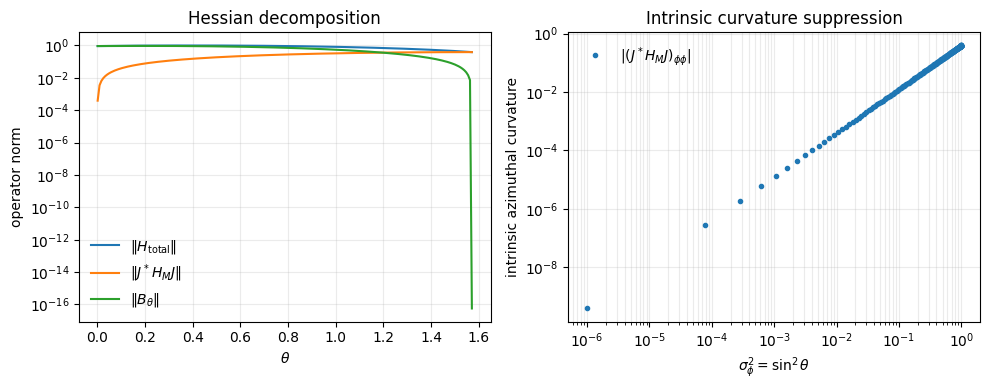

In [27]:
def plot_validation_V_hessian(df: pd.DataFrame, filename: str = "fig_validationV_hessian_appendix.pdf"):
    fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.0))
    ax = axes[0]
    ax.plot(df["theta"], df["norm_total"], label=r"$\|H_{\mathrm{total}}\|$")
    ax.plot(df["theta"], df["norm_intrinsic"], label=r"$\|J^*H_MJ\|$")
    ax.plot(df["theta"], df["norm_embedding"], label=r"$\|B_\theta\|$")
    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("operator norm")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False)
    ax.set_title("Hessian decomposition")

    ax = axes[1]
    ax.plot(df["sigma_phi"]**2, np.abs(df["intrinsic_phiphi"]), marker=".", linestyle="none", label=r"$|(J^*H_MJ)_{\phi\phi}|$")
    ax.set_xlabel(r"$\sigma_\phi^2=\sin^2\theta$")
    ax.set_ylabel("intrinsic azimuthal curvature")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False)
    ax.set_title("Intrinsic curvature suppression")
    fig.tight_layout()
    path = os.path.join(FIG_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    return path

plot_validation_V_hessian(valV_df)

Second-order suppression scaling
alpha = 1.500000000000
Pearson r = 1.000000, p = 0.00e+00
Spearman rho = 1.000000, p = 0.00e+00


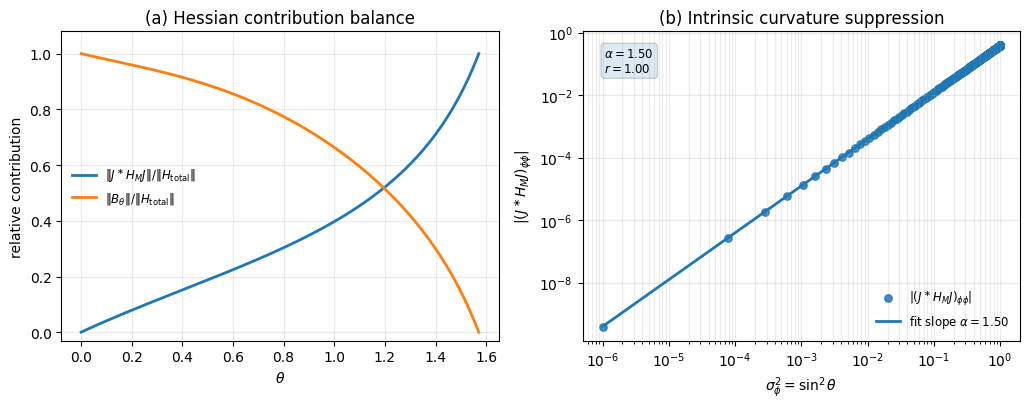

Saved:
figures_jacobian_qfim\fig_validationV_second_order_suppression.pdf


In [28]:
# ==========================================================
# Validation V — paper-ready second-order geometric suppression
# ==========================================================

from scipy.stats import pearsonr, spearmanr
import numpy as np
import matplotlib.pyplot as plt
import os

def plot_validation_V_second_order_suppression(
    df: pd.DataFrame,
    filename: str = "fig_validationV_second_order_suppression.pdf",
):
    eps = 1e-18

    theta = df["theta"].to_numpy(dtype=float)

    total = np.maximum(df["norm_total"].to_numpy(dtype=float), eps)
    intrinsic = np.maximum(df["norm_intrinsic"].to_numpy(dtype=float), eps)
    embedding = np.maximum(df["norm_embedding"].to_numpy(dtype=float), eps)

    sigma2 = df["sigma_phi"].to_numpy(dtype=float) ** 2
    curv_phi = np.abs(df["intrinsic_phiphi"].to_numpy(dtype=float))

    # Avoid numerical-floor dominated points.
    mask = (
        np.isfinite(sigma2)
        & np.isfinite(curv_phi)
        & (sigma2 > 1e-10)
        & (curv_phi > 1e-12)
    )

    logx = np.log10(sigma2[mask])
    logy = np.log10(curv_phi[mask])

    alpha, beta = np.polyfit(logx, logy, 1)
    r, p = pearsonr(logx, logy)
    rho, ps = spearmanr(logx, logy)

    xx = np.linspace(logx.min(), logx.max(), 250)
    yy = alpha * xx + beta

    ratio_intrinsic = intrinsic / total
    ratio_embedding = embedding / total

    print("Second-order suppression scaling")
    print(f"alpha = {alpha:.12f}")
    print(f"Pearson r = {r:.6f}, p = {p:.2e}")
    print(f"Spearman rho = {rho:.6f}, p = {ps:.2e}")

    fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))

    # ------------------------------------------------------
    # Panel A: relative Hessian contributions
    # ------------------------------------------------------
    ax = axes[0]

    ax.plot(
        theta,
        ratio_intrinsic,
        linewidth=2.0,
        label=r"$\|J^\ast H_MJ\|/\|H_{\mathrm{total}}\|$",
    )

    ax.plot(
        theta,
        ratio_embedding,
        linewidth=2.0,
        label=r"$\|B_\theta\|/\|H_{\mathrm{total}}\|$",
    )

    ax.set_xlabel(r"$\theta$")
    ax.set_ylabel("relative contribution")
    ax.set_ylim(-0.03, 1.08)
    ax.set_title("(a) Hessian contribution balance")
    ax.grid(True, alpha=0.25)
    ax.legend(frameon=False, fontsize=8.5)

    # ------------------------------------------------------
    # Panel B: intrinsic curvature scaling
    # ------------------------------------------------------
    ax = axes[1]

    ax.scatter(
        sigma2[mask],
        curv_phi[mask],
        s=28,
        alpha=0.85,
        label=r"$|(J^\ast H_MJ)_{\phi\phi}|$",
    )

    ax.plot(
        10**xx,
        10**yy,
        "-",
        linewidth=2.0,
        label=rf"fit slope $\alpha={alpha:.2f}$",
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"$\sigma_\phi^2=\sin^2\theta$")
    ax.set_ylabel(r"$|(J^\ast H_MJ)_{\phi\phi}|$")
    ax.set_title("(b) Intrinsic curvature suppression")
    ax.grid(True, which="both", alpha=0.25)
    ax.legend(frameon=False, fontsize=8.5)

    ax.text(
        0.05,
        0.95,
        (
            rf"$\alpha={alpha:.2f}$" "\n"
            rf"$r={r:.2f}$"
        ),
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox=dict(boxstyle="round", alpha=0.15),
    )

    fig.tight_layout()

    path = os.path.join(FIG_DIR, filename)

    fig.savefig(path, bbox_inches="tight")
    fig.savefig(path.replace(".pdf", ".png"), dpi=300, bbox_inches="tight")

    plt.show()

    return path


path_valV_second_order = plot_validation_V_second_order_suppression(valV_df)

print("Saved:")
print(path_valV_second_order)

# Export all generated figures and data

This cell saves dataframes as CSV files and lists all figures. For production, rerun previous cells with larger `n_samples`, wider `ns`, and more depths.

In [29]:
DATA_DIR = "data_jacobian_qfim"
os.makedirs(DATA_DIR, exist_ok=True)

for name, df in [
    ("validation0_modal_identity", val0_df),
    ("validationI_suppression", valI_df),
    ("validationII_scaling", valII_df),
    ("validationII_permutations", perm_df),
    ("validationIII_scaling", valIII_df),
    ("validationIV_predictive", valIV_df),
    ("validationV_hessian", valV_df),
]:
    df.to_csv(os.path.join(DATA_DIR, f"{name}.csv"), index=False)

print("Figures:")
for f in sorted(os.listdir(FIG_DIR)):
    print(" -", os.path.join(FIG_DIR, f))

print("\nData:")
for f in sorted(os.listdir(DATA_DIR)):
    print(" -", os.path.join(DATA_DIR, f))

Figures:
 - figures_jacobian_qfim\fig_predictive_power_spectral_alignment.pdf
 - figures_jacobian_qfim\fig_predictive_power_spectral_alignment.png
 - figures_jacobian_qfim\fig_validation0_modal_identity.pdf
 - figures_jacobian_qfim\fig_validationIII_scaling_local_global_v3.pdf
 - figures_jacobian_qfim\fig_validationIII_scaling_local_global_v3.png
 - figures_jacobian_qfim\fig_validationIII_scaling_local_global_v4.pdf
 - figures_jacobian_qfim\fig_validationIII_scaling_local_global_v4.png
 - figures_jacobian_qfim\fig_validationII_dla_same_jacobian_different.pdf
 - figures_jacobian_qfim\fig_validationII_dla_same_jacobian_different.png
 - figures_jacobian_qfim\fig_validationII_jacobian_geometry_permutations.pdf
 - figures_jacobian_qfim\fig_validationII_jacobian_geometry_permutations.png
 - figures_jacobian_qfim\fig_validationII_permutation_distribution.pdf
 - figures_jacobian_qfim\fig_validationIV_predictive_training.pdf
 - figures_jacobian_qfim\fig_validationIV_predictor_ranking_v3.pdf
 - 